# Segunda entrega: Pensamiento Crítico II y Estadística Bayesiana

**Universidad Externado de Colombia · Facultad de Matemáticas · Pregrado en Ciencia de Datos**

**Proyecto:** Demanda de artículos para el hogar y gestión del inventario, un enfoque bayesiano


**Integrantes:** Juan Esteban Jiménez Aristizábal, David Quijano, Juan Esteban Zambrano, Juan Angel Triana Olarte

**Datos:** FRED, Banco de la Reserva Federal de San Luis (https://fred.stlouisfed.org), con series del U.S. Census Bureau y del Bureau of Economic Analysis.

## Sección 0. Configuración

Aquí se cargan las librerías, se buscan los archivos y se definen las variables del modelo. Si solo van a cambiar algo, que sea `RUTA_DRIVE`.

In [2]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
from pathlib import Path
import shutil
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import optimize, stats
from scipy.special import gammaln

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

# Si los archivos están en Drive, escribir la carpeta, por ejemplo "/content/drive/MyDrive/bayes/proyecto".
# Si se deja vacío, se buscan en la carpeta de trabajo de Colab (/content).
RUTA_DRIVE = "/content/drive/MyDrive/Sem 4/bayes/proyecto"

SEMILLA = 2026   # fija la aleatoriedad para poder repetir los resultados
N_SIM = 4000     # simulaciones para la predictiva a priori
ARCHIVOS = ["base_hogar_modelo.csv", "diccionario_variables.csv"]

# Variable respuesta y explicativas (todas en crecimiento mensual, 100*diff(log), salvo la razón de inventarios)
Y = "crec_muebles_hogar"
X = [
    "crec_electro",
    "crec_sin_tienda",
    "crec_construccion",
    "crec_tiendas_generales",
    "crec_gasolineras",
    "crec_ingreso_disponible",
    "razon_inv_ventas_rezago1",
    "crec_muebles_hogar_rezago1",
]
CUANTI = [Y] + X
rng = np.random.default_rng(SEMILLA)

# Carpeta de trabajo
if RUTA_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    CARPETA = Path(RUTA_DRIVE)
else:
    CARPETA = Path.cwd()

faltan = [a for a in ARCHIVOS if not (CARPETA / a).exists()]
if faltan:
    try:
        from google.colab import files
        print("Faltan archivos, súbelos ahora:", faltan)
        files.upload()
        CARPETA = Path.cwd()
    except ImportError:
        pass
faltan = [a for a in ARCHIVOS if not (CARPETA / a).exists()]
if faltan:
    raise FileNotFoundError(f"No se encontraron {faltan} en {CARPETA}")

CARPETA_SALIDAS = CARPETA / "salidas_entrega2"
CARPETA_SALIDAS.mkdir(exist_ok=True)
print("Carpeta de datos:", CARPETA)
print("Carpeta de salidas:", CARPETA_SALIDAS)


def titulo(texto):
    print("\n" + "=" * 78)
    print(texto)
    print("=" * 78)


def guardar_figura(nombre):
    plt.tight_layout()
    plt.savefig(CARPETA_SALIDAS / nombre, dpi=160, bbox_inches="tight")
    plt.show()
    print(f"   [figura guardada] {nombre}")


def guardar_tabla(tabla, nombre, indice=True):
    tabla.to_csv(CARPETA_SALIDAS / nombre, index=indice, encoding="utf-8-sig")
    print(f"   [tabla guardada] {nombre}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Carpeta de datos: /content/drive/MyDrive/Sem 4/bayes/proyecto
Carpeta de salidas: /content/drive/MyDrive/Sem 4/bayes/proyecto/salidas_entrega2


# Parte A. Planteamiento del problema, pregunta, justificación y objetivos
(Numerales 1 a 4 del PDF. Se califican en Pensamiento Crítico y en Estadística Bayesiana.)

## 1. Planteamiento del problema

Una comercializadora de artículos para el hogar tiene que decidir cada cierto tiempo cuánto inventario mantener y cuánto pedir, y esa decisión depende de cuánto se espera vender. Si se pide de menos, los productos se agotan y se pierden ventas, y si se pide de más, la mercancía se queda en bodega ocupando espacio y dinero. En la primera entrega trabajamos esta situación desde el caso de un producto nuevo, que no tiene historial propio de ventas. Para esta etapa del proyecto cambiamos la escala: en lugar de mirar un solo producto miramos el sector. La razón es práctica, porque antes de pronosticar un producto específico hace falta entender cómo se mueve la demanda del conjunto de artículos para el hogar y cuánta incertidumbre trae consigo, ya que esa es la referencia con la que una empresa decide si un pedido es razonable. Para esto usamos datos mensuales de ventas minoristas de Estados Unidos entre marzo de 1992 y julio de 2026, publicados por el Census Bureau y distribuidos a través de FRED.

La demanda de muebles y artículos del hogar no se mueve sola. Se relaciona con lo que pasa en otras categorías del comercio, como electrónica y electrodomésticos, materiales de construcción y tiendas de mercancía general, con el ingreso disponible de los hogares, con el crecimiento de las ventas sin tienda y con la relación entre inventarios y ventas del comercio minorista, que indica cuántos meses de ventas hay almacenados. Además, la serie tiene episodios extremos. En marzo y abril de 2020 el crecimiento mensual de las ventas de muebles cayó 25 y 71 puntos en la escala de log-diferencias, y en mayo y junio subió 60 y 33 puntos, mientras que en el resto de la muestra la desviación estándar del crecimiento es de apenas 1.8 puntos. Los años posteriores también fueron más inestables que los anteriores, en parte por lo que parecen ser los pagos de estímulo a los hogares en 2020 y 2021, que se notan en la serie de ingreso disponible. Un modelo que ignore estos episodios, o que los trate como observaciones normales, va a entregar estimaciones y rangos de incertidumbre poco confiables, justo lo que necesita quien decide un inventario.

Dentro de la empresa, los encargados de compras e inventario quieren evitar tanto el desabastecimiento como el exceso, el área comercial suele querer pedidos más grandes para cumplir sus metas, y el área financiera cuida el dinero que queda inmovilizado en bodega. Sin un criterio objetivo sobre cuánta variación es normal en la demanda del sector, estas diferencias se resuelven por intuición, como ya veníamos describiendo desde la primera entrega.

Al revisar la literatura nos dimos cuenta de que, en pronóstico de demanda, se ha estudiado poco qué tan confiable es la predicción, algo que Van Steenbergen y Mes señalan para el caso de productos nuevos y que es justo lo que necesita quien maneja un inventario para decidir con confianza. Por otro lado, Lenza y Primiceri (2022) muestran, para modelos macroeconómicos, que descartar las observaciones extremas de 2020 puede ser aceptable para estimar parámetros, pero que subestima la incertidumbre cuando se quiere pronosticar. Estas dos ideas nos llevan a un enfoque bayesiano, que entrega una distribución completa para cada parámetro y para la predicción, y que permite tratar los datos extremos de forma explícita en lugar de borrarlos.

## 2. Pregunta de investigación

Como la empresa necesita saber qué tanto puede variar la demanda y qué la mueve, la pregunta que guía el proyecto es la siguiente:

**¿De qué manera el crecimiento de las ventas de otras categorías del comercio minorista, el ingreso disponible de los hogares y el nivel de inventarios del comercio explican el crecimiento mensual de las ventas de muebles y artículos para el hogar en Estados Unidos, y qué tanta incertidumbre queda en esa explicación bajo un enfoque de inferencia bayesiana con verosimilitud robusta a los datos extremos de 2020?**

## 3. Justificación

Este proyecto es útil porque las decisiones de inventario se siguen tomando con una sola cifra, el pronóstico puntual, cuando lo que más pesa en el costo es qué tan lejos puede quedar la demanda real de esa cifra. Un rango creíble para el crecimiento de las ventas le sirve a un encargado de compras para fijar un inventario de seguridad con un criterio y no con una corazonada, y les da al área comercial y al área financiera un número común sobre el cual discutir.

El enfoque bayesiano es adecuado por tres razones. La primera es que entrega la incertidumbre de cada parámetro como una distribución, de modo que podemos decir cuál es la probabilidad de que una categoría del comercio tenga un efecto positivo sobre las ventas de muebles, y no solo si un coeficiente resulta significativo o no. La segunda es que nos deja incorporar información previa razonable, por ejemplo que ningún efecto individual debería ser enorme, mediante distribuciones a priori débilmente informativas que además estabilizan la estimación. La tercera es que permite escribir la verosimilitud de acuerdo con lo que se ve en los datos, que son colas pesadas, mediante una t de Student y una escala de error mayor en los meses de 2020, en lugar de eliminar esos meses.

Aunque tenemos 389 meses de entrenamiento, que no es una muestra pequeña, los efectos que buscamos son débiles frente al ruido de la serie, y en ese caso importa más cuantificar bien la incertidumbre que reportar un valor puntual. Aclaramos desde ahora que el modelo describe asociaciones entre series del mismo mes y no relaciones causales, por lo que sus resultados se interpretan como una forma de entender el comportamiento conjunto del sector.

## 4. Objetivos

### 4.1 Objetivo general

Estimar un modelo de regresión bayesiano, con verosimilitud t de Student robusta a los meses extremos de 2020, para explicar el crecimiento mensual de las ventas minoristas de muebles y artículos para el hogar en Estados Unidos y cuantificar la incertidumbre de esa explicación.

### 4.2 Objetivos específicos

1. Realizar un análisis exploratorio de los datos para describir sus distribuciones, valores atípicos, volatilidad y correlaciones.
2. Determinar, con la evidencia del análisis exploratorio, la familia de distribuciones adecuada para la función de verosimilitud, incluyendo el tratamiento de los meses de 2020.
3. Especificar una distribución a priori para cada parámetro del modelo, con sus hiperparámetros y el argumento que la respalda, y comprobar que son coherentes mediante una predictiva a priori.
4. Aproximar la distribución posterior con el algoritmo de Metropolis-Hastings, verificar la convergencia de las cadenas y validar el modelo con los últimos 24 meses reservados (entrega final).
5. Interpretar los resultados en términos de la decisión de inventario (entrega final).

### 4.3 Alcance y limitaciones

El proyecto trabaja con series agregadas de Estados Unidos, ajustadas estacionalmente, por lo que sus conclusiones no se trasladan directamente a una empresa en particular ni a otro país. Los valores más recientes de las series del Census son estimaciones adelantadas que luego se revisan, y por eso dejamos por fuera agosto de 2026. Las variables explicativas son del mismo mes que la respuesta, así que el modelo mide asociación y no causalidad. Tampoco contamos con datos de precios ni de la competencia.

# Parte B. Análisis exploratorio de datos (EDA)
(Numeral 5 del PDF. Se califica en Estadística Bayesiana.)

Todo el análisis de esta parte usa solo los 389 meses de entrenamiento. La base de prueba se separa en 5.3 y no se explora.

### 5.1 Carga y validación de la base

Antes de analizar nada revisamos que la base esté bien armada: sin vacíos ni duplicados, con meses consecutivos y con las transformaciones bien calculadas. El crecimiento mensual es 100 por la diferencia del logaritmo de la serie en niveles, es decir, aproximadamente el cambio porcentual de un mes al siguiente.

In [5]:
titulo("5.1 Carga y validación")

df = pd.read_csv(CARPETA / "base_hogar_modelo.csv", parse_dates=["fecha"])
df = df.sort_values("fecha").reset_index(drop=True)

print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")
print(f"Periodo: {df['fecha'].min():%Y-%m} a {df['fecha'].max():%Y-%m}")
print(f"Valores nulos: {int(df.isna().sum().sum())}")
print(f"Filas duplicadas: {int(df.duplicated().sum())} | Fechas duplicadas: {int(df['fecha'].duplicated().sum())}")

meses = df["fecha"].dt.year * 12 + df["fecha"].dt.month
print(f"Huecos en la serie mensual: {int((meses.diff().dropna() != 1).sum())}")

rezago_ok = np.allclose(df[Y].shift(1).iloc[1:], df["crec_muebles_hogar_rezago1"].iloc[1:])
print(f"El rezago de Y coincide con Y desplazada un mes: {rezago_ok}")

recalculo = 100 * np.log(df["nivel_muebles_hogar"]).diff()
print(f"Máxima diferencia con 100*diff(log(nivel)): {(recalculo - df[Y]).iloc[1:].abs().max():.4f}")


5.1 Carga y validación
Filas: 413 | Columnas: 19
Periodo: 1992-03 a 2026-07
Valores nulos: 0
Filas duplicadas: 0 | Fechas duplicadas: 0
Huecos en la serie mensual: 0
El rezago de Y coincide con Y desplazada un mes: True
Máxima diferencia con 100*diff(log(nivel)): 0.0000


### 5.2 Diccionario de variables

Los nombres de las columnas son códigos que armamos a partir de los códigos de FRED. Esta tabla dice qué es cada una, de qué serie viene y qué transformación tiene.

In [6]:
titulo("5.2 Diccionario de variables")

dicc = pd.read_csv(CARPETA / "diccionario_variables.csv")
pd.set_option("display.max_colwidth", 80)
print(dicc.to_string(index=False))
guardar_tabla(dicc, "tabla_diccionario.csv", indice=False)


5.2 Diccionario de variables
                   columna codigo_FRED        rol                     transformacion                                                                    descripcion
             muebles_hogar      RSFHFS          Y      nivel (millones USD, desest.)                               Ventas minoristas: muebles y artículos del hogar
                   electro       RSEAS          X      nivel (millones USD, desest.)                             Ventas minoristas: electrónica y electrodomésticos
                sin_tienda       RSNSR          X      nivel (millones USD, desest.)                        Ventas minoristas: minoristas sin tienda (canal online)
              construccion    RSBMGESD          X      nivel (millones USD, desest.)                         Ventas minoristas: materiales de construcción y jardín
         tiendas_generales       RSGMS          X      nivel (millones USD, desest.)                                Ventas minoristas: tiendas de merc

### 5.3 Partición entrenamiento y prueba

La partición es por tiempo y no aleatoria, porque en una serie de tiempo no tiene sentido entrenar con el futuro. Los últimos 24 meses quedan reservados para validar el modelo en la entrega final.

In [7]:
titulo("5.3 Partición entrenamiento y prueba")

entren = df[df["conjunto"] == "entrenamiento"].copy().reset_index(drop=True)
prueba = df[df["conjunto"] == "prueba"].copy().reset_index(drop=True)   # no se explora aquí

print(f"Entrenamiento: {len(entren)} meses ({entren['fecha'].min():%Y-%m} a {entren['fecha'].max():%Y-%m})")
print(f"Prueba (reservada): {len(prueba)} meses ({prueba['fecha'].min():%Y-%m} a {prueba['fecha'].max():%Y-%m})")


5.3 Partición entrenamiento y prueba
Entrenamiento: 389 meses (1992-03 a 2024-07)
Prueba (reservada): 24 meses (2024-08 a 2026-07)


### 5.4 Preparación: meses de COVID y submuestra de meses normales

La base trae una variable `covid_2020` que vale 1 entre marzo y junio de 2020. Con ella armamos dos versiones de los datos: la completa, que es la que usará el modelo principal, y una de meses normales, que sirve para ver cómo se comportan las variables cuando no hay episodios extremos. En la segunda quitamos también julio de 2020, porque la variable de rezago de ese mes es el valor extremo de junio y contaminaría los resultados. La submuestra de meses normales no es un modelo alternativo, es solo una forma de mirar los datos.

Para el análisis de la volatilidad también marcamos dos regímenes: antes de marzo de 2020 y desde julio de 2020.

In [8]:
titulo("5.4 Preparación")

entren["es_covid"] = entren["covid_2020"] == 1
entren["decada"] = (entren["fecha"].dt.year // 10 * 10).astype(str) + "s"
entren["excluir"] = entren["es_covid"] | entren["es_covid"].shift(1, fill_value=False)
normales = entren[~entren["excluir"]].copy()

print(f"Meses marcados como COVID: {int(entren['es_covid'].sum())}")
print(entren.loc[entren["es_covid"], ["fecha", Y]].assign(fecha=lambda t: t["fecha"].dt.strftime("%Y-%m")).to_string(index=False))
print(f"\nMuestra de meses normales: {len(normales)} (se quitan {int(entren['excluir'].sum())}: los 4 meses COVID y julio de 2020)")


5.4 Preparación
Meses marcados como COVID: 4
  fecha  crec_muebles_hogar
2020-03          -25.109767
2020-04          -70.623637
2020-05           59.537019
2020-06           32.842852

Muestra de meses normales: 384 (se quitan 5: los 4 meses COVID y julio de 2020)


### 5.5 Resumen estadístico

Para cada variable cuantitativa se calcula media, mediana, desviación estándar, mínimo, máximo, asimetría y curtosis. La curtosis que reporta pandas es la curtosis en exceso, es decir que una distribución normal vale 0, y valores grandes indican colas pesadas. La asimetría mide si la cola más larga está hacia la derecha (positiva) o hacia la izquierda (negativa).

In [9]:
titulo("5.5 Resumen estadístico")


def resumen(d):
    return pd.DataFrame({
        "media": d[CUANTI].mean(),
        "mediana": d[CUANTI].median(),
        "desv_std": d[CUANTI].std(),
        "minimo": d[CUANTI].min(),
        "maximo": d[CUANTI].max(),
        "asimetria": d[CUANTI].skew(),
        "curtosis_exceso": d[CUANTI].kurt(),
    }).round(3)


res_con = resumen(entren)
res_sin = resumen(normales)
print("MUESTRA COMPLETA DE ENTRENAMIENTO (con COVID):")
print(res_con.to_string())
print("\nMESES NORMALES (sin COVID):")
print(res_sin.to_string())
guardar_tabla(res_con, "tabla_estadisticos_con_covid.csv")
guardar_tabla(res_sin, "tabla_estadisticos_sin_covid.csv")


5.5 Resumen estadístico
MUESTRA COMPLETA DE ENTRENAMIENTO (con COVID):
                            media  mediana  desv_std  minimo  maximo  asimetria  curtosis_exceso
crec_muebles_hogar          0.234    0.233     5.456 -70.624  59.537     -2.022          112.677
crec_electro                0.160    0.298     4.452 -58.384  34.130     -4.500           87.692
crec_sin_tienda             0.781    0.747     2.081 -12.263  12.243     -0.031            7.822
crec_construccion           0.355    0.245     2.155  -8.135  13.519      1.145            8.066
crec_tiendas_generales      0.345    0.333     1.340 -10.975   8.518     -0.633           18.487
crec_gasolineras            0.377    0.396     3.643 -25.991  12.496     -2.029           13.670
crec_ingreso_disponible     0.397    0.395     1.833 -15.910  21.118      2.854           67.609
razon_inv_ventas_rezago1    1.491    1.490     0.142   1.090   1.750     -0.548           -0.092
crec_muebles_hogar_rezago1  0.236    0.233     5.456 -7

### 5.6 Serie de tiempo de la respuesta y volatilidad

El primer gráfico muestra el crecimiento mensual a lo largo del tiempo, con los meses de COVID marcados. El segundo muestra la desviación estándar por década. Con esto se revisa si la variabilidad es constante, porque la verosimilitud del modelo supone una escala de error que no cambia, salvo que se indique lo contrario. También se compara la desviación antes de marzo de 2020 con la de después de julio de 2020 y se aplica la prueba de Levene, que contrasta si dos grupos tienen la misma varianza.


5.6 Serie de tiempo y volatilidad


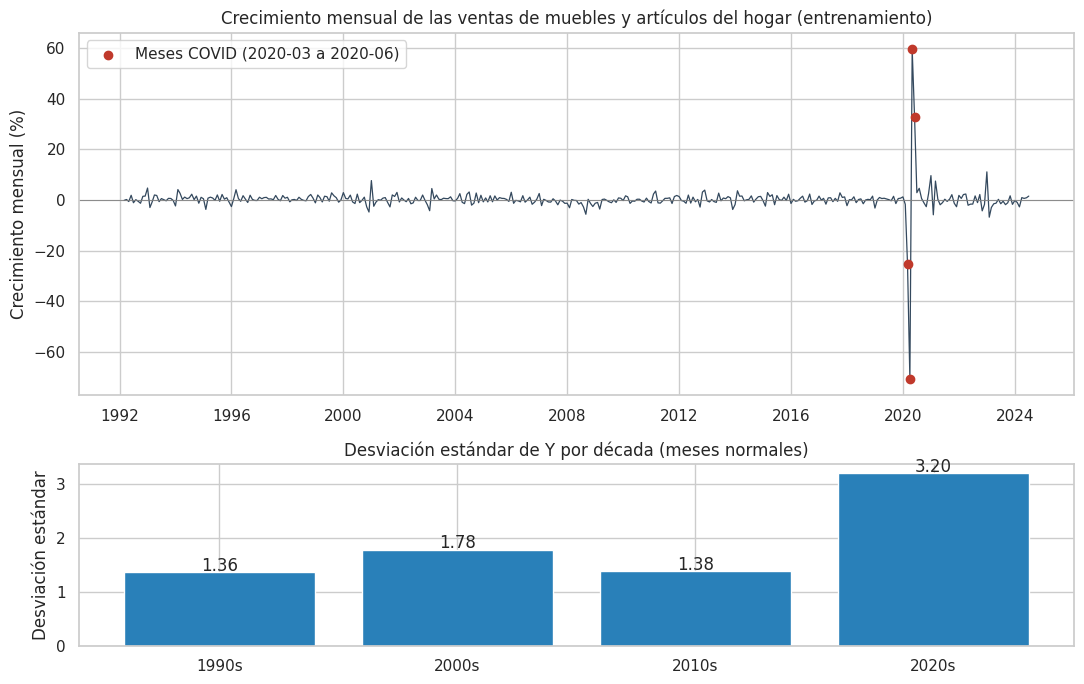

   [figura guardada] fig_B1_serie_tiempo.png
   [tabla guardada] tabla_desv_por_decada.csv
Desviación estándar por década (meses normales):
decada
1990s    1.36
2000s    1.78
2010s    1.38
2020s    3.20

Antes de 2020-03: desv. std = 1.54 (336 meses)
Desde 2020-07:    desv. std = 3.25 (49 meses)
Cociente de desviaciones (después/antes) = 2.10
Prueba de Levene (igualdad de varianzas): estadístico = 31.20, p = 4.42e-08


In [10]:
titulo("5.6 Serie de tiempo y volatilidad")

cov = entren[entren["es_covid"]]
fig, ax = plt.subplots(2, 1, figsize=(11, 7), gridspec_kw={"height_ratios": [2, 1]})
ax[0].plot(entren["fecha"], entren[Y], color="#34495e", lw=0.9)
ax[0].scatter(cov["fecha"], cov[Y], color="#c0392b", zorder=3, label="Meses COVID (2020-03 a 2020-06)")
ax[0].axhline(0, color="gray", lw=0.6)
ax[0].set_title("Crecimiento mensual de las ventas de muebles y artículos del hogar (entrenamiento)")
ax[0].set_ylabel("Crecimiento mensual (%)")
ax[0].legend()

sd_dec = normales.groupby("decada")[Y].std()
ax[1].bar(sd_dec.index, sd_dec.values, color="#2980b9")
ax[1].set_title("Desviación estándar de Y por década (meses normales)")
ax[1].set_ylabel("Desviación estándar")
for i, v in enumerate(sd_dec.values):
    ax[1].text(i, v + 0.03, f"{v:.2f}", ha="center")
guardar_figura("fig_B1_serie_tiempo.png")
guardar_tabla(sd_dec.round(3).to_frame("desv_std_meses_normales"), "tabla_desv_por_decada.csv")

antes = entren.loc[entren["fecha"] < "2020-03-01", Y]
despues = entren.loc[entren["fecha"] >= "2020-07-01", Y]
lev = stats.levene(antes, despues)
print("Desviación estándar por década (meses normales):")
print(sd_dec.round(2).to_string())
print(f"\nAntes de 2020-03: desv. std = {antes.std():.2f} ({len(antes)} meses)")
print(f"Desde 2020-07:    desv. std = {despues.std():.2f} ({len(despues)} meses)")
print(f"Cociente de desviaciones (después/antes) = {despues.std() / antes.std():.2f}")
print(f"Prueba de Levene (igualdad de varianzas): estadístico = {lev.statistic:.2f}, p = {lev.pvalue:.2e}")

### 5.7 Boxplots

Los boxplots permiten ver la variabilidad entre grupos y los valores atípicos. En este proyecto no hay regiones ni modelos de producto, así que el grupo natural es la década. El panel izquierdo muestra la respuesta por década, con y sin los meses de COVID, y el derecho muestra todas las variables explicativas estandarizadas para compararlas en una sola escala. Los puntos fuera de los bigotes son valores atípicos según la regla de Tukey (más de 1.5 veces el rango intercuartil).


5.7 Boxplots


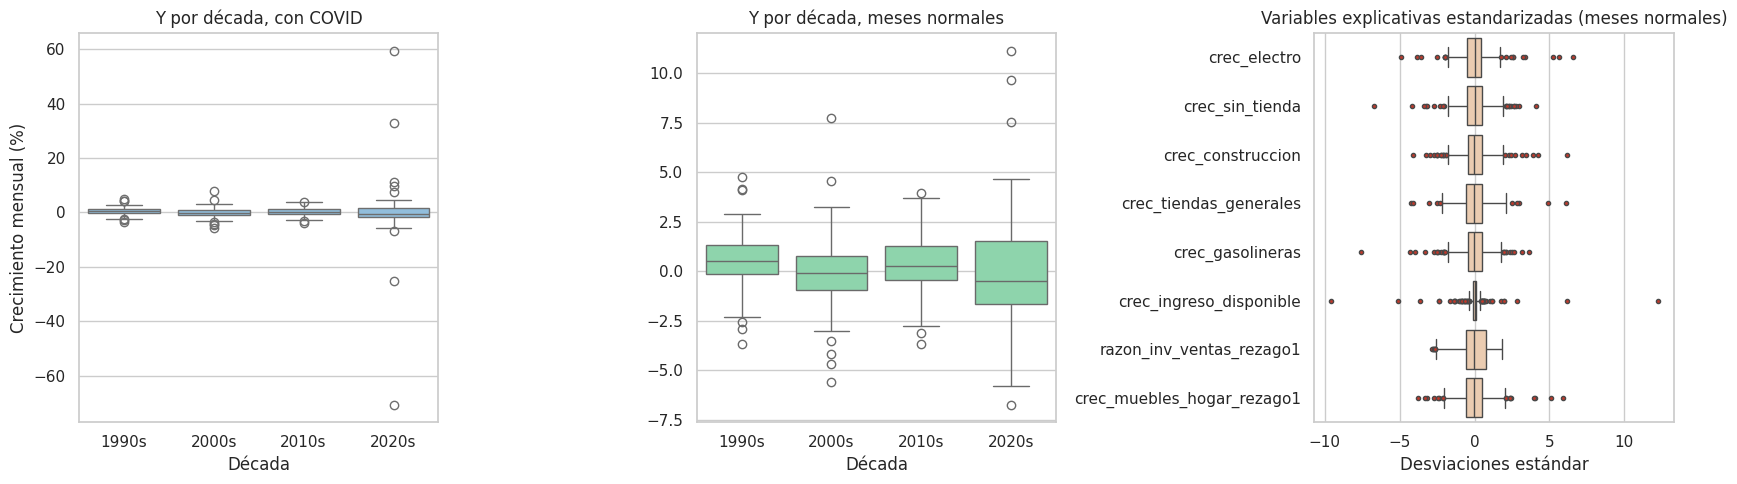

   [figura guardada] fig_B2_boxplots.png
Valores atípicos de Y por la regla de Tukey (meses normales): 16 de 384 (límites -3.69 y 4.05)


In [11]:
titulo("5.7 Boxplots")

orden = sorted(entren["decada"].unique())
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
sns.boxplot(data=entren, x="decada", y=Y, order=orden, ax=ax[0], color="#85c1e9")
ax[0].set_title("Y por década, con COVID")
ax[0].set_xlabel("Década"); ax[0].set_ylabel("Crecimiento mensual (%)")
sns.boxplot(data=normales, x="decada", y=Y, order=orden, ax=ax[1], color="#82e0aa")
ax[1].set_title("Y por década, meses normales")
ax[1].set_xlabel("Década"); ax[1].set_ylabel("")
z = (normales[X] - normales[X].mean()) / normales[X].std()
sns.boxplot(data=z, orient="h", ax=ax[2], color="#f5cba7",
            flierprops=dict(marker="o", markersize=3, markerfacecolor="#c0392b"))
ax[2].set_title("Variables explicativas estandarizadas (meses normales)")
ax[2].set_xlabel("Desviaciones estándar")
guardar_figura("fig_B2_boxplots.png")

q1, q3 = normales[Y].quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_out = int(((normales[Y] < lim_inf) | (normales[Y] > lim_sup)).sum())
print(f"Valores atípicos de Y por la regla de Tukey (meses normales): {n_out} de {len(normales)} "
      f"(límites {lim_inf:.2f} y {lim_sup:.2f})")

### 5.8 Dispersión con línea de tendencia

Cada gráfico enfrenta la respuesta con una variable explicativa. Se dibujan dos rectas, una con todos los puntos (roja) y otra solo con los meses normales (verde). Los puntos rojos son los meses de COVID. Se hacen dos versiones, una completa y otra con zoom sobre la nube de meses normales, porque los puntos de COVID quedan tan lejos que aplastan el resto.


5.8 Dispersión con tendencia


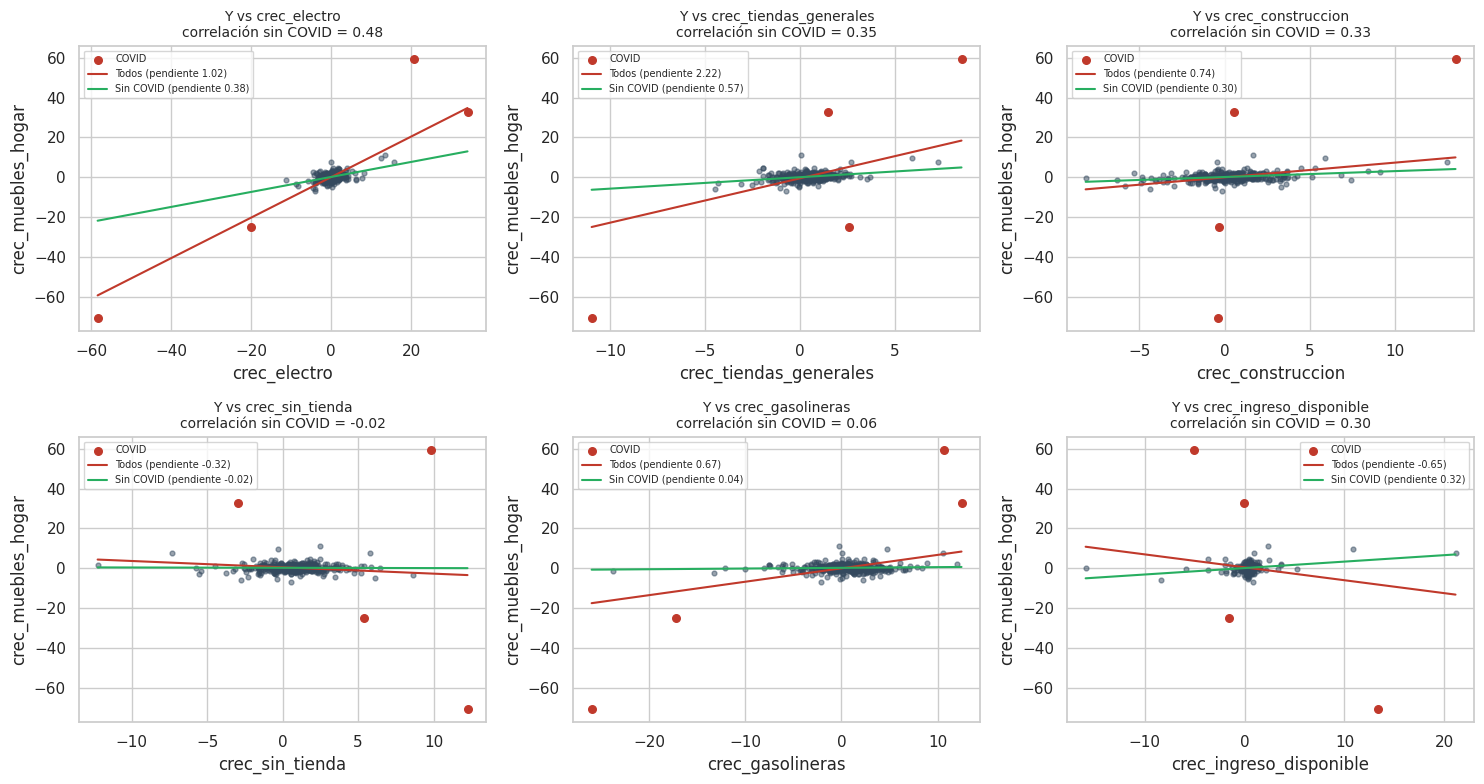

   [figura guardada] fig_B3_dispersion.png


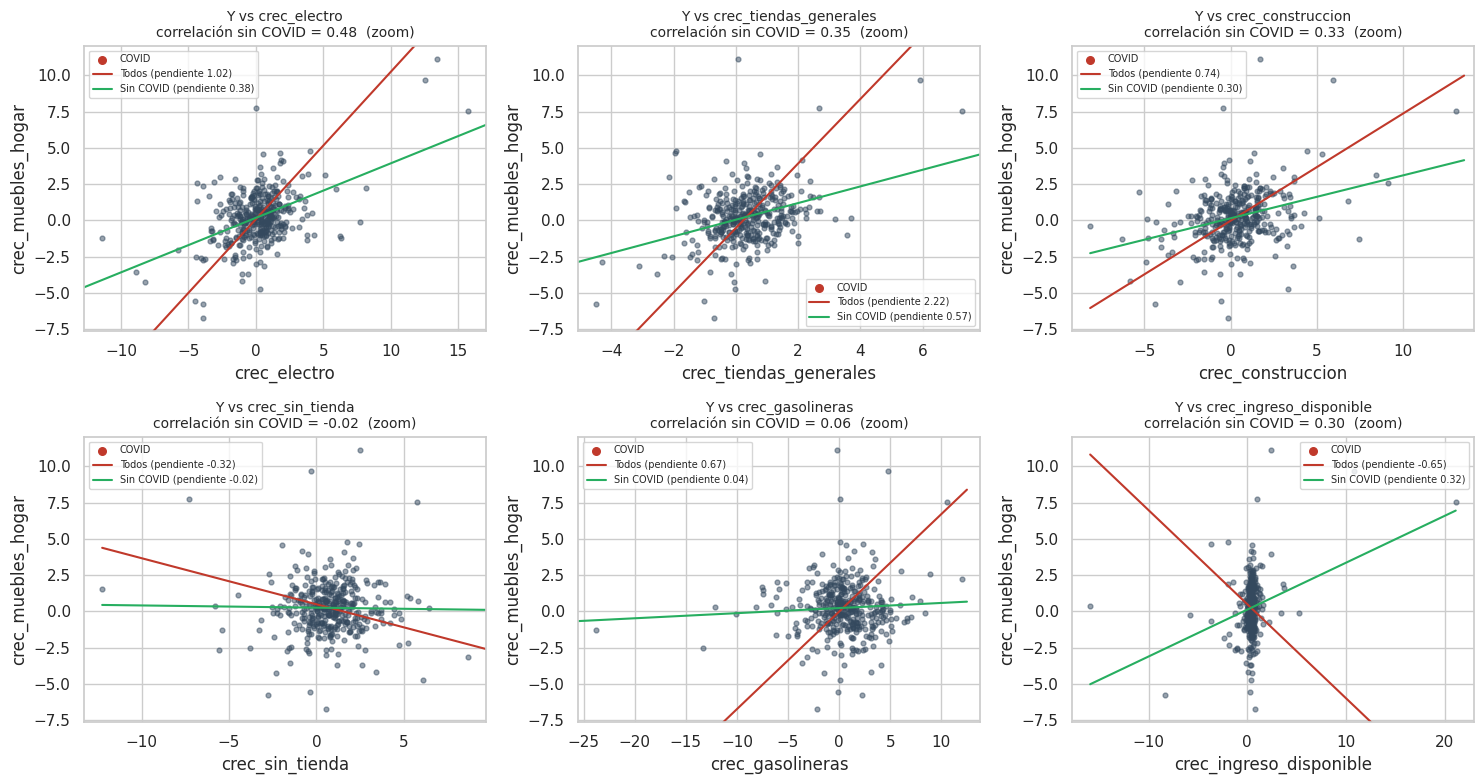

   [figura guardada] fig_B3_dispersion_zoom.png
   [tabla guardada] tabla_pendientes_dispersion.csv
                         pendiente_todos  pendiente_sin_covid  corr_sin_covid
crec_electro                       1.016                0.376           0.481
crec_tiendas_generales             2.225                0.574           0.355
crec_construccion                  0.741                0.296           0.331
crec_sin_tienda                   -0.318               -0.015          -0.016
crec_gasolineras                   0.673                0.035           0.061
crec_ingreso_disponible           -0.649                0.323           0.298


In [12]:
titulo("5.8 Dispersión con tendencia")

vars_scatter = ["crec_electro", "crec_tiendas_generales", "crec_construccion",
                "crec_sin_tienda", "crec_gasolineras", "crec_ingreso_disponible"]
pend = {}
for zoom in (False, True):
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for ax, v in zip(axes.ravel(), vars_scatter):
        ax.scatter(normales[v], normales[Y], s=12, alpha=0.5, color="#34495e")
        ax.scatter(cov[v], cov[Y], s=30, color="#c0392b", label="COVID")
        xs = np.linspace(entren[v].min(), entren[v].max(), 100)
        b_all = np.polyfit(entren[v], entren[Y], 1)
        b_sin = np.polyfit(normales[v], normales[Y], 1)
        ax.plot(xs, np.polyval(b_all, xs), color="#c0392b", lw=1.5, label=f"Todos (pendiente {b_all[0]:.2f})")
        ax.plot(xs, np.polyval(b_sin, xs), color="#27ae60", lw=1.5, label=f"Sin COVID (pendiente {b_sin[0]:.2f})")
        r_sin = np.corrcoef(normales[v], normales[Y])[0, 1]
        ax.set_title(f"Y vs {v}\ncorrelación sin COVID = {r_sin:.2f}" + ("  (zoom)" if zoom else ""), fontsize=10)
        if zoom:
            mx_ = 0.05 * (normales[v].max() - normales[v].min())
            my_ = 0.05 * (normales[Y].max() - normales[Y].min())
            ax.set_xlim(normales[v].min() - mx_, normales[v].max() + mx_)
            ax.set_ylim(normales[Y].min() - my_, normales[Y].max() + my_)
        ax.set_xlabel(v); ax.set_ylabel(Y)
        ax.legend(fontsize=7)
        pend[v] = {"pendiente_todos": b_all[0], "pendiente_sin_covid": b_sin[0], "corr_sin_covid": r_sin}
    guardar_figura("fig_B3_dispersion_zoom.png" if zoom else "fig_B3_dispersion.png")
guardar_tabla(pd.DataFrame(pend).T.round(3), "tabla_pendientes_dispersion.csv")
print(pd.DataFrame(pend).T.round(3).to_string())

### 5.9 Histogramas y gráficos de densidad

El histograma con la curva de densidad estimada (KDE) permite ver la forma de cada distribución. Primero se muestra la respuesta con y sin COVID, y después todas las variables en meses normales. Aquí la pregunta de fondo para el enfoque bayesiano es qué distribución usar en la verosimilitud: Normal, Poisson, Gamma o Log-Normal.


5.9 Histogramas y KDE


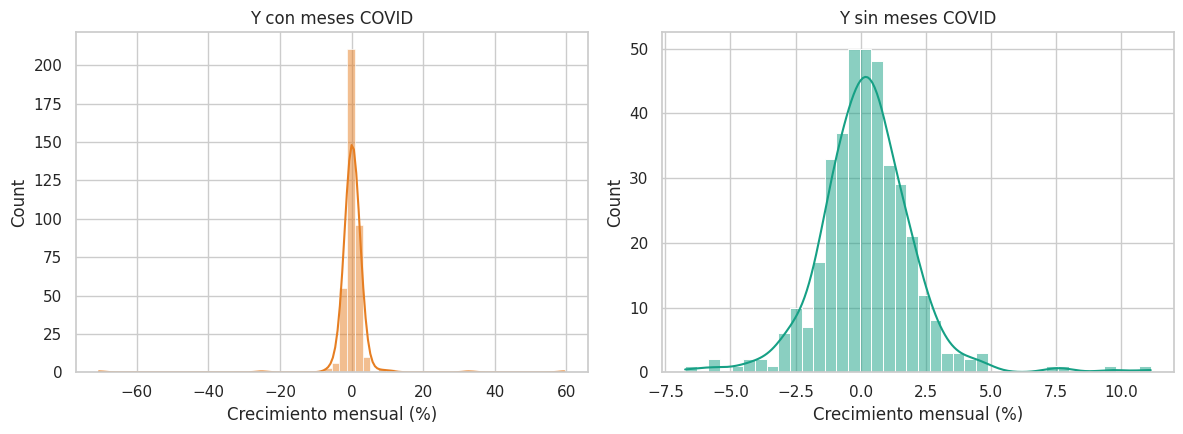

   [figura guardada] fig_B4_hist_kde_Y.png


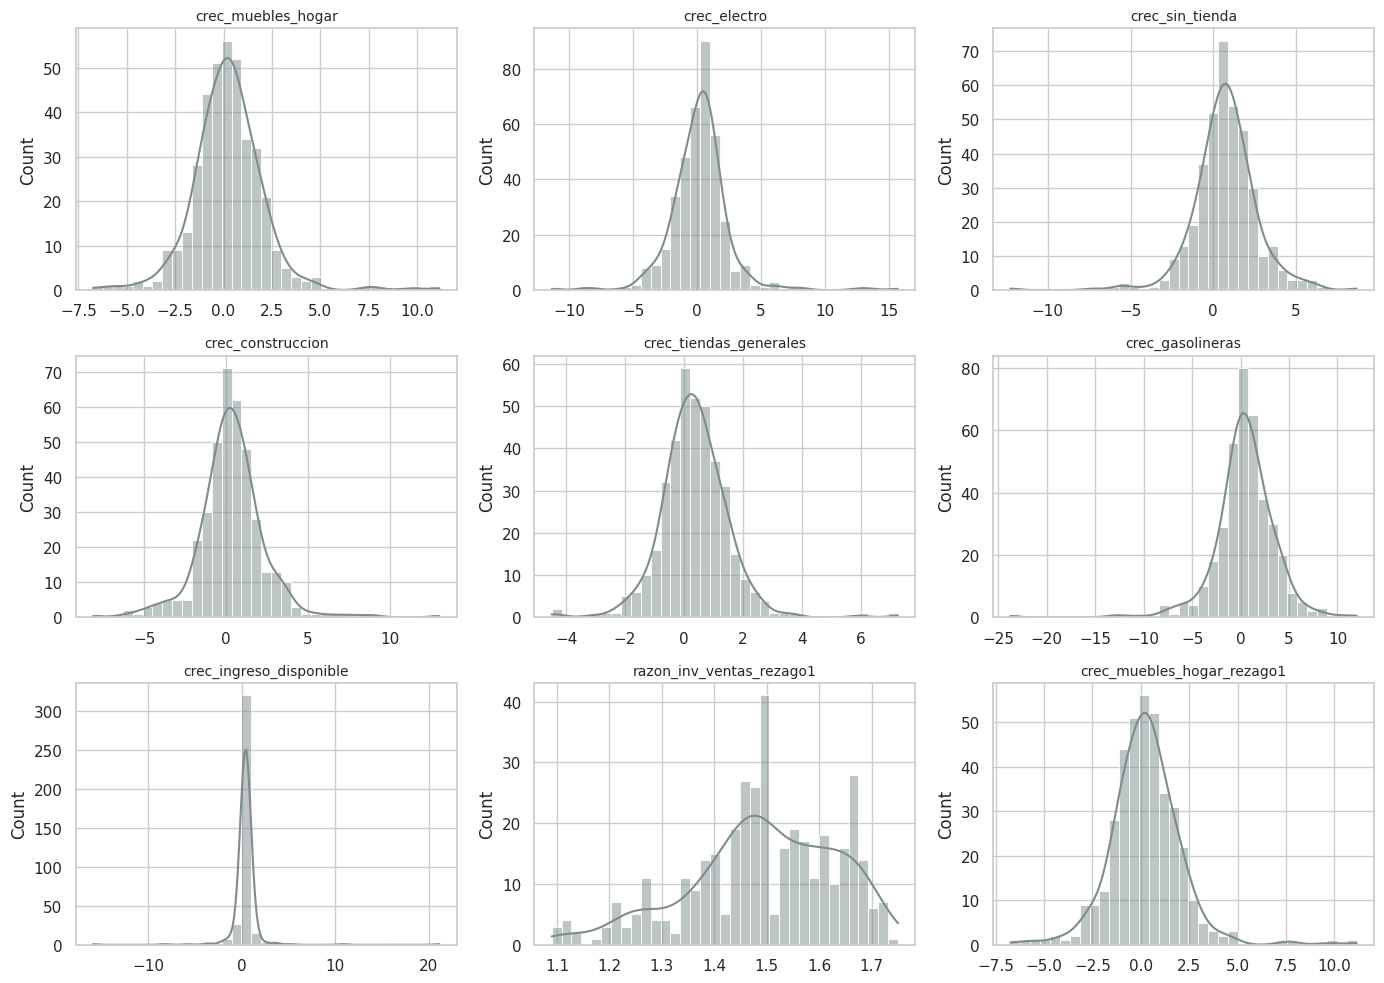

   [figura guardada] fig_B4_hist_kde_variables.png
Y toma valores negativos en 172 de 389 meses.
Por eso Poisson, Gamma y Log-Normal, que solo admiten valores positivos, no sirven para modelar Y.


In [13]:
titulo("5.9 Histogramas y KDE")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(entren[Y], bins=60, kde=True, ax=ax[0], color="#e67e22")
ax[0].set_title("Y con meses COVID")
sns.histplot(normales[Y], bins=40, kde=True, ax=ax[1], color="#16a085")
ax[1].set_title("Y sin meses COVID")
for a in ax:
    a.set_xlabel("Crecimiento mensual (%)")
guardar_figura("fig_B4_hist_kde_Y.png")

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for a, v in zip(axes.ravel(), CUANTI):
    sns.histplot(normales[v], bins=35, kde=True, ax=a, color="#7f8c8d")
    a.set_title(v, fontsize=10)
    a.set_xlabel("")
guardar_figura("fig_B4_hist_kde_variables.png")

neg = int((entren[Y] < 0).sum())
print(f"Y toma valores negativos en {neg} de {len(entren)} meses.")
print("Por eso Poisson, Gamma y Log-Normal, que solo admiten valores positivos, no sirven para modelar Y.")

### 5.10 Elección de la distribución de la verosimilitud

Se ajustan tres distribuciones a la respuesta por máxima verosimilitud: Normal, t de Student y Laplace. Se comparan con el AIC, que premia el ajuste y castiga la cantidad de parámetros (menor es mejor). También se hacen gráficos cuantil-cuantil (QQ), donde los puntos deben seguir la diagonal si la distribución es la correcta, y la prueba de Shapiro-Wilk de normalidad, que rechaza normalidad cuando el valor p es muy pequeño.


5.10 Ajuste de distribuciones a Y
distribucion            parametros  log_verosimilitud    AIC   muestra
      Normal        (0.234, 5.449)            -1211.5 2426.9 con COVID
   Student-t (2.186, 0.199, 1.138)             -794.1 1594.1 con COVID
     Laplace        (0.233, 1.756)             -877.7 1759.3 con COVID
      Normal        (0.238, 1.839)             -778.7 1561.4 sin COVID
   Student-t (3.624, 0.196, 1.243)             -740.3 1486.5 sin COVID
     Laplace        (0.227, 1.282)             -745.6 1495.1 sin COVID
   [tabla guardada] tabla_ajuste_distribuciones.csv
Shapiro-Wilk (con COVID): p = 2.54e-35
Shapiro-Wilk (sin COVID): p = 4.79e-13


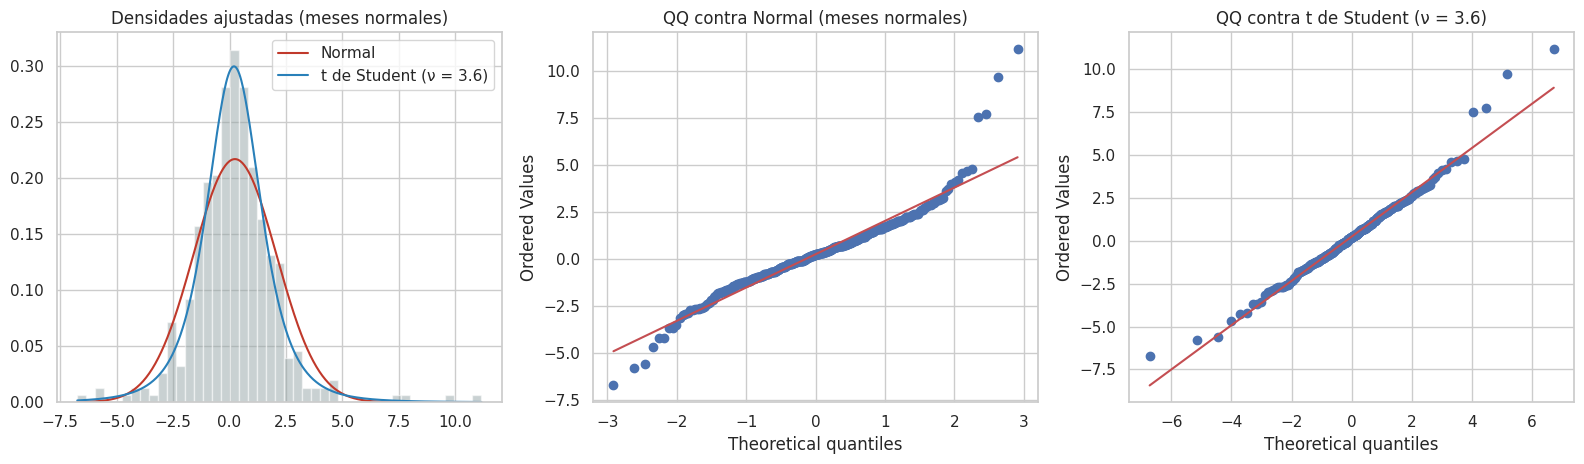

   [figura guardada] fig_B5_ajuste_distribuciones.png


In [14]:
titulo("5.10 Ajuste de distribuciones a Y")


def ajustar(y):
    filas = []
    for nombre, dist, k in [("Normal", stats.norm, 2), ("Student-t", stats.t, 3), ("Laplace", stats.laplace, 2)]:
        par = dist.fit(y)
        ll = float(np.sum(dist.logpdf(y, *par)))
        filas.append({"distribucion": nombre, "parametros": tuple(round(float(p), 3) for p in par),
                      "log_verosimilitud": round(ll, 1), "AIC": round(2 * k - 2 * ll, 1)})
    return pd.DataFrame(filas)


ajustes = pd.concat([ajustar(entren[Y].values).assign(muestra="con COVID"),
                     ajustar(normales[Y].values).assign(muestra="sin COVID")], ignore_index=True)
print(ajustes.to_string(index=False))
guardar_tabla(ajustes, "tabla_ajuste_distribuciones.csv", indice=False)
for etiqueta, d in [("con COVID", entren), ("sin COVID", normales)]:
    print(f"Shapiro-Wilk ({etiqueta}): p = {stats.shapiro(d[Y]).pvalue:.2e}")

y_n = normales[Y].values
nu_n, loc_n, esc_n = stats.t.fit(y_n)
mu_n, sd_n = stats.norm.fit(y_n)
grid = np.linspace(y_n.min(), y_n.max(), 400)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
ax[0].hist(y_n, bins=45, density=True, alpha=0.5, color="#95a5a6")
ax[0].plot(grid, stats.norm.pdf(grid, mu_n, sd_n), color="#c0392b", label="Normal")
ax[0].plot(grid, stats.t.pdf(grid, nu_n, loc_n, esc_n), color="#2980b9", label=f"t de Student (ν = {nu_n:.1f})")
ax[0].set_title("Densidades ajustadas (meses normales)")
ax[0].legend()
stats.probplot(y_n, dist="norm", plot=ax[1])
ax[1].set_title("QQ contra Normal (meses normales)")
stats.probplot(y_n, dist=stats.t, sparams=(nu_n,), plot=ax[2])
ax[2].set_title(f"QQ contra t de Student (ν = {nu_n:.1f})")
guardar_figura("fig_B5_ajuste_distribuciones.png")

### 5.11 Matriz de correlaciones

Se grafican las correlaciones de Pearson entre todas las variables cuantitativas, con COVID a la izquierda y sin COVID a la derecha. Sirve para ver qué variables se relacionan con la respuesta y si las explicativas se parecen entre sí, lo que causaría problemas de colinealidad.


5.11 Matriz de correlaciones


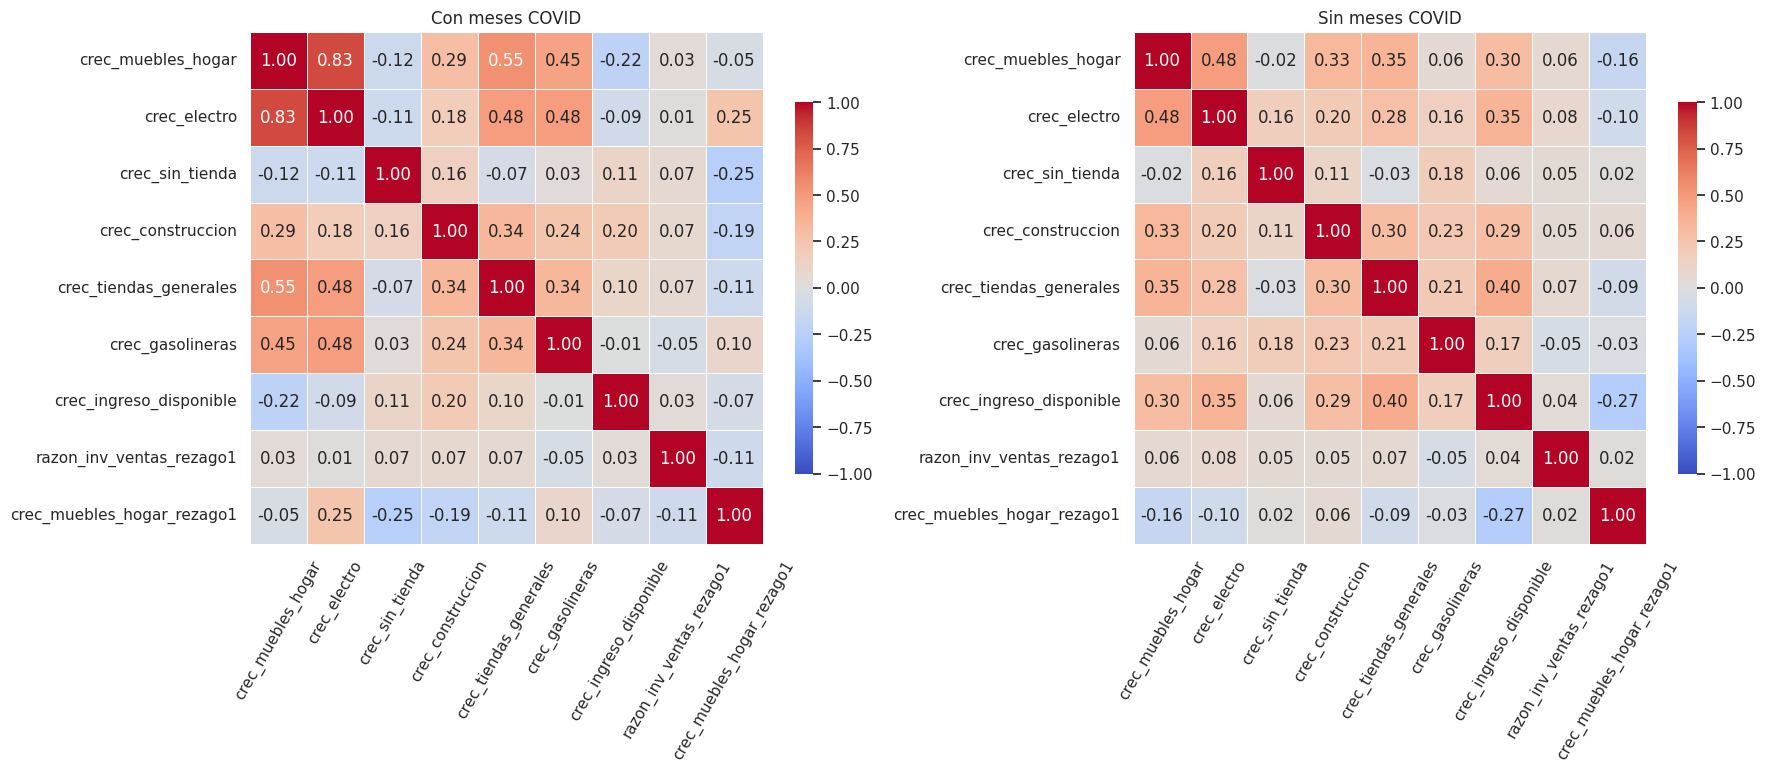

   [figura guardada] fig_B6_heatmap_correlaciones.png
   [tabla guardada] tabla_correlaciones_con_covid.csv
   [tabla guardada] tabla_correlaciones_sin_covid.csv
Correlación de cada variable con Y:
                            con_COVID  sin_COVID
crec_electro                     0.83       0.48
crec_tiendas_generales           0.55       0.35
crec_construccion                0.29       0.33
crec_ingreso_disponible         -0.22       0.30
razon_inv_ventas_rezago1         0.03       0.06
crec_gasolineras                 0.45       0.06
crec_sin_tienda                 -0.12      -0.02
crec_muebles_hogar_rezago1      -0.05      -0.16


In [15]:
titulo("5.11 Matriz de correlaciones")

corr_con = entren[CUANTI].corr()
corr_sin = normales[CUANTI].corr()
fig, ax = plt.subplots(1, 2, figsize=(18, 7.5))
for a, c, t in [(ax[0], corr_con, "Con meses COVID"), (ax[1], corr_sin, "Sin meses COVID")]:
    sns.heatmap(c, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True,
                linewidths=0.4, cbar_kws={"shrink": 0.7}, ax=a)
    a.set_title(t)
    a.tick_params(axis="x", rotation=60)
guardar_figura("fig_B6_heatmap_correlaciones.png")
guardar_tabla(corr_con.round(3), "tabla_correlaciones_con_covid.csv")
guardar_tabla(corr_sin.round(3), "tabla_correlaciones_sin_covid.csv")

comp = pd.DataFrame({"con_COVID": corr_con[Y], "sin_COVID": corr_sin[Y]}).drop(index=Y).round(2)
print("Correlación de cada variable con Y:")
print(comp.sort_values("sin_COVID", ascending=False).to_string())

### 5.12 Autocorrelación (ACF y PACF)

Como los datos son una serie de tiempo, hay que revisar si el crecimiento de un mes se relaciona con el de meses anteriores. La ACF mide la correlación de la serie con sus propios rezagos, y la PACF lo mismo pero descontando el efecto de los rezagos intermedios. Las líneas rojas son bandas de ±1.96/√n: barras fuera de ellas indican autocorrelación distinta de cero.


5.12 Autocorrelación


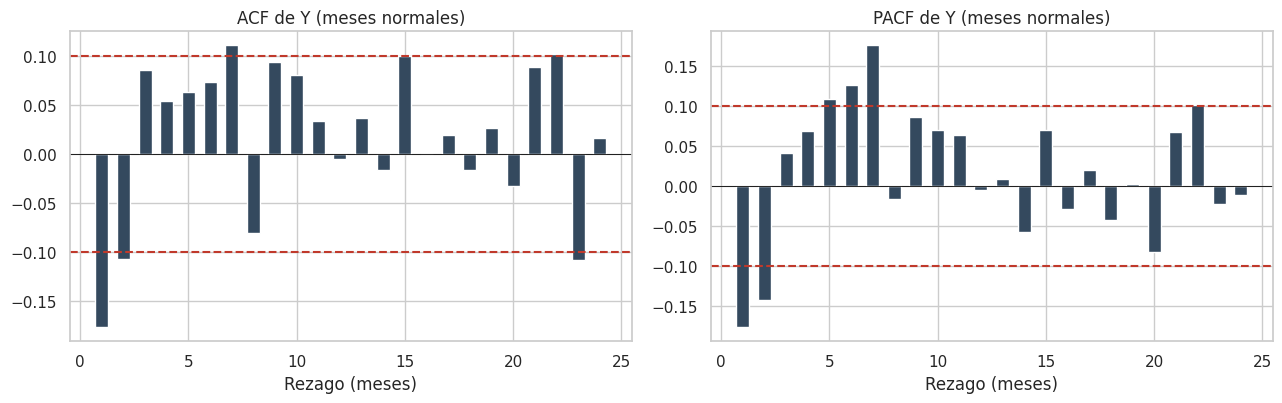

   [figura guardada] fig_B7_acf_pacf.png
Autocorrelación en el rezago 1: -0.18 | rezago 12: -0.00
Banda de ±0.10. Rezagos fuera de la banda: [1, 2, 7, 15, 22, 23]


In [16]:
titulo("5.12 Autocorrelación")


def acf(x, nlags):
    x = np.asarray(x) - np.mean(x)
    den = np.sum(x ** 2)
    return np.array([np.sum(x[k:] * x[: len(x) - k]) / den for k in range(nlags + 1)])


def pacf(x, nlags):
    r = acf(x, nlags)
    phi = np.zeros((nlags + 1, nlags + 1))
    salida = [1.0, r[1]]
    phi[1, 1] = r[1]
    for k in range(2, nlags + 1):
        num = r[k] - sum(phi[k - 1, j] * r[k - j] for j in range(1, k))
        den = 1 - sum(phi[k - 1, j] * r[j] for j in range(1, k))
        phi[k, k] = num / den
        for j in range(1, k):
            phi[k, j] = phi[k - 1, j] - phi[k, k] * phi[k - 1, k - j]
        salida.append(phi[k, k])
    return np.array(salida)


NLAGS = 24
y_acf = normales[Y].values
banda = 1.96 / np.sqrt(len(y_acf))
a_vals, p_vals = acf(y_acf, NLAGS), pacf(y_acf, NLAGS)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for a, vals, t in [(ax[0], a_vals, "ACF de Y (meses normales)"), (ax[1], p_vals, "PACF de Y (meses normales)")]:
    a.bar(range(1, NLAGS + 1), vals[1:], color="#34495e", width=0.6)
    a.axhline(banda, color="#c0392b", ls="--")
    a.axhline(-banda, color="#c0392b", ls="--")
    a.axhline(0, color="black", lw=0.6)
    a.set_title(t)
    a.set_xlabel("Rezago (meses)")
guardar_figura("fig_B7_acf_pacf.png")
fuera = [k for k in range(1, NLAGS + 1) if abs(a_vals[k]) > banda]
print(f"Autocorrelación en el rezago 1: {a_vals[1]:.2f} | rezago 12: {a_vals[12]:.2f}")
print(f"Banda de ±{banda:.2f}. Rezagos fuera de la banda: {fuera}")

### 5.13 Multicolinealidad (VIF)

El factor de inflación de la varianza (VIF) de una variable explicativa se calcula como 1 / (1 - R²), donde R² sale de regresar esa variable contra las demás. Una regla práctica es que valores por debajo de 5 son tranquilos. Si hay colinealidad fuerte, la posterior de los coeficientes queda muy dispersa y correlacionada.

In [17]:
titulo("5.13 VIF")


def calcular_vif(d):
    c = np.corrcoef(d[X].values.T)
    return pd.Series(np.diag(np.linalg.inv(c)), index=X)


vif = pd.DataFrame({"VIF_con_covid": calcular_vif(entren), "VIF_sin_covid": calcular_vif(normales)}).round(2)
print(vif.to_string())
guardar_tabla(vif, "tabla_vif.csv")


5.13 VIF
                            VIF_con_covid  VIF_sin_covid
crec_electro                         1.73           1.22
crec_sin_tienda                      1.12           1.08
crec_construccion                    1.27           1.21
crec_tiendas_generales               1.56           1.31
crec_gasolineras                     1.38           1.13
crec_ingreso_disponible              1.08           1.43
razon_inv_ventas_rezago1             1.02           1.02
crec_muebles_hogar_rezago1           1.26           1.11
   [tabla guardada] tabla_vif.csv


### 5.14 Resumen de hallazgos del EDA

Esta celda junta los números que se usan en el documento y los guarda en un archivo de texto. Sirve para no tener que copiarlos a mano desde las tablas.

In [18]:
titulo("5.14 Resumen del EDA")

mejor = ajustes[ajustes["muestra"] == "sin COVID"].sort_values("AIC").iloc[0]["distribucion"]
lineas_eda = [
    f"Base: {len(df)} meses ({df['fecha'].min():%Y-%m} a {df['fecha'].max():%Y-%m}). Entrenamiento: {len(entren)}; prueba reservada: {len(prueba)}.",
    f"Y con COVID: desviación {res_con.loc[Y, 'desv_std']}, asimetría {res_con.loc[Y, 'asimetria']}, curtosis en exceso {res_con.loc[Y, 'curtosis_exceso']}.",
    f"Y sin COVID: desviación {res_sin.loc[Y, 'desv_std']}, asimetría {res_sin.loc[Y, 'asimetria']}, curtosis en exceso {res_sin.loc[Y, 'curtosis_exceso']}.",
    "Desviación estándar de Y por década (meses normales): " + ", ".join(f"{k}: {v:.2f}" for k, v in sd_dec.items()) + ".",
    f"Antes de 2020-03 la desviación es {antes.std():.2f} y desde 2020-07 es {despues.std():.2f} (Levene p = {lev.pvalue:.1e}).",
    f"Distribución con menor AIC: {mejor}, con {nu_n:.1f} grados de libertad en meses normales. Poisson, Gamma y Log-Normal no aplican porque Y es negativa en {neg} meses.",
    f"Correlación con Y sin COVID: electrónica {corr_sin.loc[Y, 'crec_electro']:.2f}, tiendas generales {corr_sin.loc[Y, 'crec_tiendas_generales']:.2f}, "
    f"construcción {corr_sin.loc[Y, 'crec_construccion']:.2f}, ingreso {corr_sin.loc[Y, 'crec_ingreso_disponible']:.2f}, razón inventarios {corr_sin.loc[Y, 'razon_inv_ventas_rezago1']:.2f}.",
    f"VIF máximo (meses normales): {vif['VIF_sin_covid'].max()}.",
    f"Autocorrelación de Y en el rezago 1: {a_vals[1]:.2f}.",
]
for l in lineas_eda:
    print("- " + l)
(CARPETA_SALIDAS / "resumen_eda.txt").write_text("\n".join(lineas_eda), encoding="utf-8")


5.14 Resumen del EDA
- Base: 413 meses (1992-03 a 2026-07). Entrenamiento: 389; prueba reservada: 24.
- Y con COVID: desviación 5.456, asimetría -2.022, curtosis en exceso 112.677.
- Y sin COVID: desviación 1.841, asimetría 0.861, curtosis en exceso 6.208.
- Desviación estándar de Y por década (meses normales): 1990s: 1.36, 2000s: 1.78, 2010s: 1.38, 2020s: 3.20.
- Antes de 2020-03 la desviación es 1.54 y desde 2020-07 es 3.25 (Levene p = 4.4e-08).
- Distribución con menor AIC: Student-t, con 3.6 grados de libertad en meses normales. Poisson, Gamma y Log-Normal no aplican porque Y es negativa en 172 meses.
- Correlación con Y sin COVID: electrónica 0.48, tiendas generales 0.35, construcción 0.33, ingreso 0.30, razón inventarios 0.06.
- VIF máximo (meses normales): 1.43.
- Autocorrelación de Y en el rezago 1: -0.18.


786

# Parte C. Primera especificación de las priors
(Numeral 6 del PDF. Se califica en Estadística Bayesiana.)

Con lo que mostró el EDA se define el modelo, y para cada parámetro se da la distribución a priori, los hiperparámetros y el argumento. Después se comprueba con una predictiva a priori que lo que se asume antes de ver los datos tenga sentido.

### 6.1 El modelo

Para cada mes $t$, la respuesta $y_t$ es el crecimiento mensual de las ventas de muebles y artículos del hogar, y $z_{jt}$ son las $j = 1, \dots, 8$ variables explicativas estandarizadas. El modelo es

$$y_t = \beta_0 + \sum_{j=1}^{8} \beta_j \, z_{jt} + \varepsilon_t, \qquad \varepsilon_t \sim t_{\nu}\big(0, \sigma_t\big)$$

La escala del error no es constante. Se escribe como

$$\sigma_t = \sigma \cdot \lambda_t \cdot \psi^{\,I(t \ge \text{jul-2020})}$$

donde $\lambda_t = \kappa_m$ en cada uno de los cuatro meses de COVID (marzo, abril, mayo y junio de 2020) y $\lambda_t = 1$ en los demás meses, y $\psi$ es un factor que permite que la volatilidad cambie desde julio de 2020.

Las razones de cada decisión salen del EDA. La t de Student se usa porque la respuesta tiene colas pesadas incluso sin COVID (secciones 5.9 y 5.10). Los factores $\kappa_m$ se usan para conservar los cuatro meses de COVID sin que deformen los demás parámetros, siguiendo la idea de Lenza y Primiceri (2022) de modelar el cambio de volatilidad de la pandemia en lugar de eliminar esos meses, lo cual subestima la incertidumbre. El factor $\psi$ se usa porque la volatilidad desde 2020 es más del doble que la anterior (sección 5.6). Los parámetros son entonces $\beta_0$, $\beta_1, \dots, \beta_8$, $\sigma$, $\nu$, $\kappa_1, \dots, \kappa_4$ y $\psi$, 16 en total.

Las variables explicativas se estandarizan con la media y la desviación de los meses normales del entrenamiento, y no con las de toda la muestra, para que una unidad signifique una desviación estándar en condiciones normales y no una desviación inflada por los meses de COVID. Esto se hace solo con datos de entrenamiento, para no filtrar información de la prueba.

In [19]:
titulo("6.2 Datos de entrenamiento y estandarización")

media_x = normales[X].mean()
desv_x = normales[X].std(ddof=0)
Z = np.column_stack([np.ones(len(entren)), ((entren[X] - media_x) / desv_x).values])
y = entren[Y].values
idx_covid = np.where(entren["es_covid"].values)[0]                       # los 4 meses COVID
post = (entren["fecha"] >= pd.Timestamp("2020-07-01")).values.astype(float)   # 1 desde julio de 2020
mask_normal = ~entren["es_covid"].values

estand = pd.DataFrame({"media_meses_normales": media_x, "desv_meses_normales": desv_x}).round(4)
print(estand.to_string())
print(f"\nMatriz de diseño Z: {Z.shape} (intercepto y {len(X)} variables estandarizadas)")
print(f"Meses COVID: {len(idx_covid)} | meses desde julio de 2020: {int(post.sum())}")
print(f"Desviación de Y: {y.std():.2f} con COVID, {y[mask_normal].std():.2f} sin los 4 meses COVID")
guardar_tabla(estand, "tabla_estandarizacion.csv")


6.2 Datos de entrenamiento y estandarización
                            media_meses_normales  desv_meses_normales
crec_electro                              0.1910               2.3512
crec_sin_tienda                           0.7229               1.9283
crec_construccion                         0.3284               2.0567
crec_tiendas_generales                    0.3459               1.1360
crec_gasolineras                          0.4224               3.1772
crec_ingreso_disponible                   0.3818               1.6940
razon_inv_ventas_rezago1                  1.4916               0.1409
crec_muebles_hogar_rezago1                0.2519               1.8424

Matriz de diseño Z: (389, 9) (intercepto y 8 variables estandarizadas)
Meses COVID: 4 | meses desde julio de 2020: 49
Desviación de Y: 5.45 con COVID, 1.84 sin los 4 meses COVID
   [tabla guardada] tabla_estandarizacion.csv


### 6.3 Tabla de priors

Esta es la tabla que va en el documento. Los hiperparámetros no se ajustaron para que la posterior salga de cierta forma. Para elegirlos se usó solo el orden de magnitud de la respuesta (desviación de unos 1.8 puntos en meses normales), que es el tipo de información que se considera legítima al construir priors débilmente informativas.

In [20]:
titulo("6.3 Especificación de las priors")

PRIORS = {
    "beta0": stats.norm(0, 1),
    "beta": stats.norm(0, 1),
    "sigma": stats.halfnorm(scale=2),
    "nu": stats.gamma(a=2, scale=1 / 0.1),
    "log_kappa": stats.halfnorm(scale=2),
    "log_psi": stats.norm(0, 1),
}

tabla_priors = pd.DataFrame([
    ["β0 (intercepto)", "Normal", "media 0, desviación 1",
     "El crecimiento medio mensual de las ventas de muebles es pequeño, cercano a 0.2 puntos. Un intercepto centrado en 0 con desviación 1 cubre valores entre -2 y 2 sin imponer ninguno."],
    ["βj, j = 1 a 8 (variables estandarizadas)", "Normal", "media 0, desviación 1",
     "Un cambio de una desviación estándar en otra categoría del comercio, o en el ingreso, no debería mover las ventas de muebles más de un par de puntos, que es la escala de Y en meses normales. Con desviación 1, la probabilidad a priori de |β| > 2 es de 4.6%. Se centra en 0 para no imponer el signo. Gelman et al. (2008) proponen priors débilmente informativas de este tipo para coeficientes de variables estandarizadas."],
    ["σ (escala del error)", "Half-Normal", "escala 2",
     "σ debe ser positiva. Con escala 2 la mediana a priori es de 1.35 y el intervalo del 90% es [0.13, 3.92], que cubre la desviación de Y en meses normales (1.8) y valores menores, esperables después de explicar parte de la variación con las X. Gelman (2006) recomienda priors débilmente informativas sobre los parámetros de escala."],
    ["ν (grados de libertad de la t)", "Gamma", "forma 2, tasa 0.1 (media 20)",
     "Permite desde colas muy pesadas (ν < 5 tiene 9% de probabilidad) hasta casi una normal (ν > 30 tiene 20%). Es la opción por defecto propuesta por Juárez y Steel (2010) para los grados de libertad de una t. El EDA sugiere un ν bajo, pero no se usa para fijar la prior."],
    ["κm, m = 1 a 4 (escala extra en mar-jun 2020)", "log κm ~ Half-Normal", "escala 2 (κm ≥ 1)",
     "Multiplica la escala del error en cada mes de COVID, siguiendo la idea de Lenza y Primiceri (2022). Se pone sobre el logaritmo para que κ sea siempre mayor o igual a 1 y para que permita factores pequeños (mediana 3.9) o muy grandes (percentil 95 cercano a 50), porque los meses de COVID se alejaron entre 14 y 39 desviaciones estándar de un mes normal."],
    ["ψ (cambio de escala desde jul-2020)", "log ψ ~ Normal", "media 0, desviación 1",
     "Centrado en ψ = 1 (sin cambio), porque a priori no sabemos si la volatilidad subió o bajó. Con desviación 1, ψ puede ir de 0.14 a 7 con 95% de probabilidad. El EDA muestra que la volatilidad es más del doble desde 2020 (secciones 5.6 y 5.7), lo que motiva incluir el parámetro, pero no se calibra con esa cifra."],
], columns=["parámetro", "distribución", "hiperparámetros", "argumento"])

pd.set_option("display.max_colwidth", 200)
for _, f in tabla_priors.iterrows():
    print(f"{f['parámetro']}\n  Distribución: {f['distribución']} | {f['hiperparámetros']}\n  Argumento: {f['argumento']}\n")
guardar_tabla(tabla_priors, "tabla_priors.csv", indice=False)

# cifras que se citan en los argumentos
print("Cifras de apoyo:")
print(f"  P(|beta| > 2) a priori = {2 * (1 - PRIORS['beta'].cdf(2)):.3f}")
print(f"  sigma: mediana {PRIORS['sigma'].median():.2f}, intervalo 90% [{PRIORS['sigma'].ppf(0.05):.2f}, {PRIORS['sigma'].ppf(0.95):.2f}]")
print(f"  nu: media {PRIORS['nu'].mean():.0f}, P(nu < 2) = {PRIORS['nu'].cdf(2):.3f}, P(nu < 5) = {PRIORS['nu'].cdf(5):.3f}, P(nu > 30) = {1 - PRIORS['nu'].cdf(30):.3f}")
print(f"  kappa: mediana {np.exp(PRIORS['log_kappa'].median()):.1f}, percentil 90 {np.exp(PRIORS['log_kappa'].ppf(0.90)):.0f}, percentil 95 {np.exp(PRIORS['log_kappa'].ppf(0.95)):.0f}")
print(f"  psi: intervalo 95% [{np.exp(PRIORS['log_psi'].ppf(0.025)):.2f}, {np.exp(PRIORS['log_psi'].ppf(0.975)):.2f}]")


6.3 Especificación de las priors
β0 (intercepto)
  Distribución: Normal | media 0, desviación 1
  Argumento: El crecimiento medio mensual de las ventas de muebles es pequeño, cercano a 0.2 puntos. Un intercepto centrado en 0 con desviación 1 cubre valores entre -2 y 2 sin imponer ninguno.

βj, j = 1 a 8 (variables estandarizadas)
  Distribución: Normal | media 0, desviación 1
  Argumento: Un cambio de una desviación estándar en otra categoría del comercio, o en el ingreso, no debería mover las ventas de muebles más de un par de puntos, que es la escala de Y en meses normales. Con desviación 1, la probabilidad a priori de |β| > 2 es de 4.6%. Se centra en 0 para no imponer el signo. Gelman et al. (2008) proponen priors débilmente informativas de este tipo para coeficientes de variables estandarizadas.

σ (escala del error)
  Distribución: Half-Normal | escala 2
  Argumento: σ debe ser positiva. Con escala 2 la mediana a priori es de 1.35 y el intervalo del 90% es [0.13, 3.92], que cubre

### 6.4 Gráficos de las priors

Las densidades muestran la forma de lo que asumimos antes de ver los datos. Van en el documento para que el lector vea qué tan amplias o concentradas son.


6.4 Gráficos de las priors


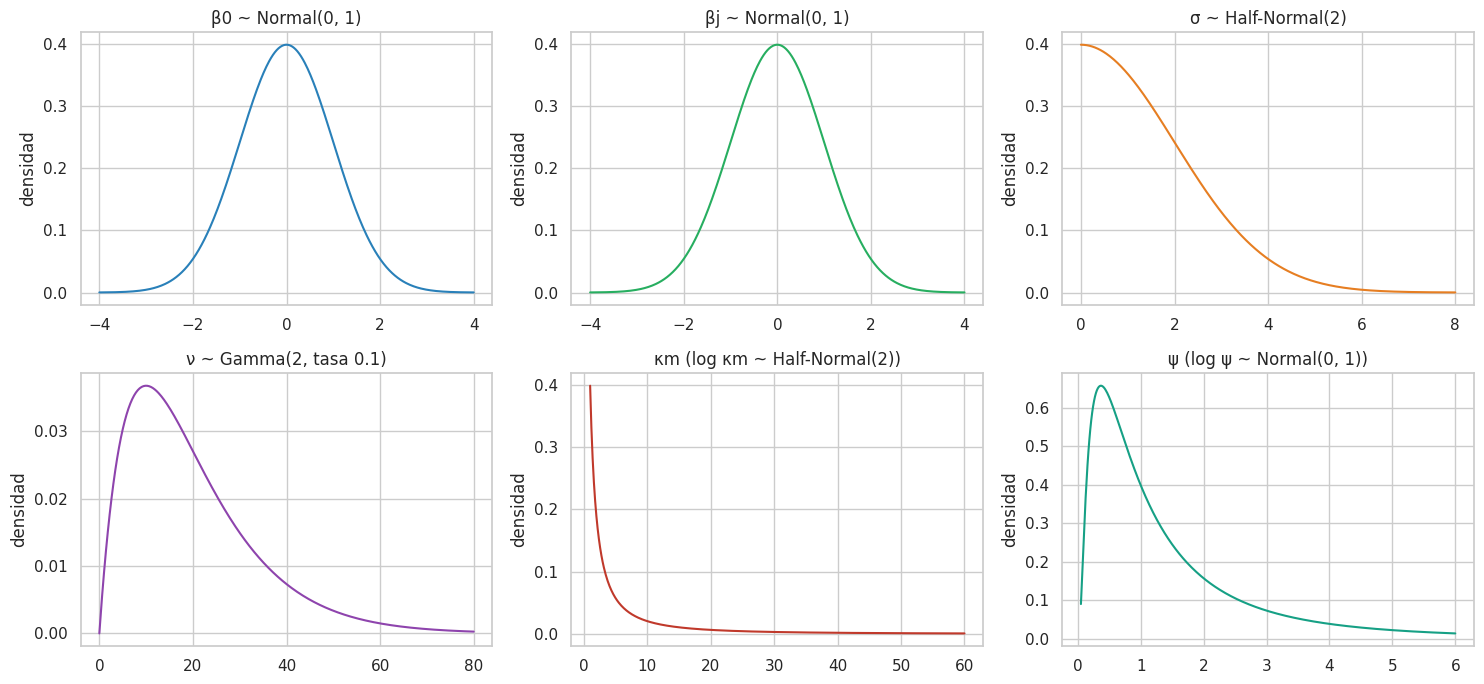

   [figura guardada] fig_C1_densidades_priors.png


In [21]:
titulo("6.4 Gráficos de las priors")

fig, ax = plt.subplots(2, 3, figsize=(15, 7))
g = np.linspace(-4, 4, 400)
ax[0, 0].plot(g, PRIORS["beta0"].pdf(g), color="#2980b9"); ax[0, 0].set_title("β0 ~ Normal(0, 1)")
ax[0, 1].plot(g, PRIORS["beta"].pdf(g), color="#27ae60"); ax[0, 1].set_title("βj ~ Normal(0, 1)")
gs = np.linspace(0, 8, 400)
ax[0, 2].plot(gs, PRIORS["sigma"].pdf(gs), color="#e67e22"); ax[0, 2].set_title("σ ~ Half-Normal(2)")
gn = np.linspace(0, 80, 400)
ax[1, 0].plot(gn, PRIORS["nu"].pdf(gn), color="#8e44ad"); ax[1, 0].set_title("ν ~ Gamma(2, tasa 0.1)")
gk = np.linspace(1, 60, 600)
dens_k = PRIORS["log_kappa"].pdf(np.log(gk)) / gk
ax[1, 1].plot(gk, dens_k, color="#c0392b"); ax[1, 1].set_title("κm (log κm ~ Half-Normal(2))")
gp = np.linspace(0.05, 6, 400)
ax[1, 2].plot(gp, PRIORS["log_psi"].pdf(np.log(gp)) / gp, color="#16a085"); ax[1, 2].set_title("ψ (log ψ ~ Normal(0, 1))")
for a in ax.ravel():
    a.set_ylabel("densidad")
guardar_figura("fig_C1_densidades_priors.png")

### 6.5 Chequeo predictivo a priori

La idea es simular parámetros desde las priors, y con ellos simular datos $y_t$ usando las variables explicativas reales. Si las priors son razonables, los datos simulados deben cubrir el rango de lo que se observa sin producir valores absurdos. Se evalúan por separado los meses normales, donde la simulación debe parecerse a una desviación de unos 1.8 puntos, y los meses de COVID, donde sí deben ser posibles valores muy extremos. Como la t con pocos grados de libertad produce valores gigantes, se reportan cuantiles y no máximos.


6.5 Chequeo predictivo a priori
Meses normales: cuantiles de y simulado contra y observado
     simulado  observado
1%     -11.00      -4.32
5%      -5.91      -2.59
25%     -2.05      -0.78
50%     -0.02       0.23
75%      2.01       1.16
95%      5.90       2.88
99%     11.07       5.21
   [tabla guardada] tabla_predictiva_priori_meses_normales.csv

Escala típica simulada en meses normales (rango intercuartil / 1.349): 2.82 | observada: 1.44
Proporción simulada con |y| < 10 en meses normales: 0.974 | observada: 0.997
Proporción simulada con |y| > 100 en meses normales: 0.0002

Meses COVID: valores observados [-25.1 -70.6  59.5  32.8]
P(|y| > 20) simulada en meses COVID: 0.527
P(|y| > 50) simulada en meses COVID: 0.195
P(|y| > 200) simulada en meses COVID: 0.0158


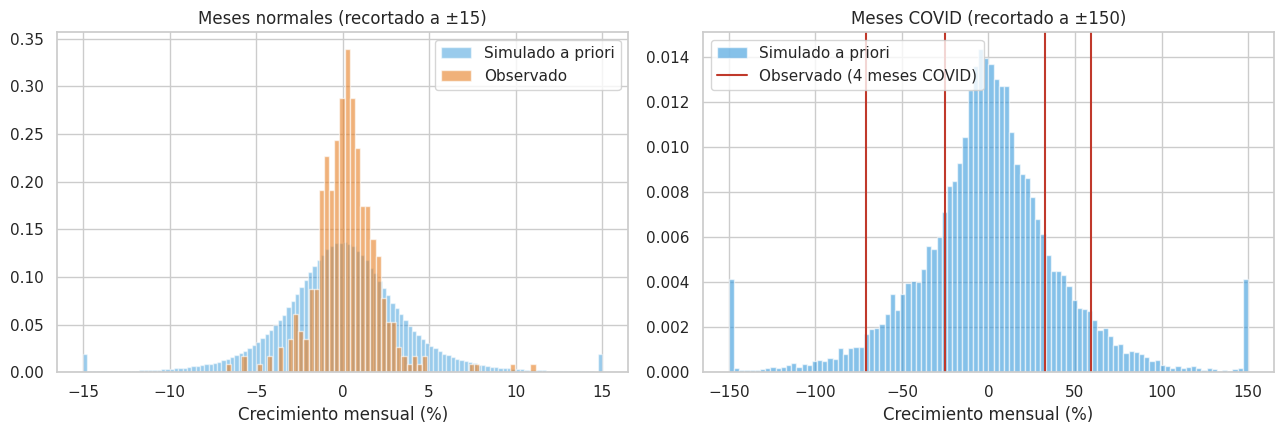

   [figura guardada] fig_C2_predictiva_priori.png


In [22]:
titulo("6.5 Chequeo predictivo a priori")


def simular(n_sim, Zm, idx_cov, post_flag, priors, rng, prior_beta=None):
    # Simula n_sim vectores de y desde la predictiva a priori. Devuelve matriz n_sim x T.
    k = Zm.shape[1] - 1
    pb = prior_beta if prior_beta is not None else priors["beta"]
    b0 = priors["beta0"].rvs(n_sim, random_state=rng)
    b = pb.rvs((n_sim, k), random_state=rng)
    s = priors["sigma"].rvs(n_sim, random_state=rng)
    nu = np.maximum(priors["nu"].rvs(n_sim, random_state=rng), 0.5)
    lk = priors["log_kappa"].rvs((n_sim, len(idx_cov)), random_state=rng)
    lpsi = priors["log_psi"].rvs(n_sim, random_state=rng)
    mu = b0[:, None] + b @ Zm[:, 1:].T
    escala = s[:, None] * np.exp(lpsi[:, None] * post_flag[None, :])
    escala[:, idx_cov] *= np.exp(lk)
    return mu + rng.standard_t(nu[:, None], size=mu.shape) * escala


ysim = simular(N_SIM, Z, idx_covid, post, PRIORS, rng)
cuantiles = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
sim_norm = ysim[:, mask_normal].ravel()
obs_norm = y[mask_normal]
tabla_pp = pd.DataFrame({"simulado": np.quantile(sim_norm, cuantiles),
                         "observado": np.quantile(obs_norm, cuantiles)}, index=[f"{int(c * 100)}%" for c in cuantiles]).round(2)
print("Meses normales: cuantiles de y simulado contra y observado")
print(tabla_pp.to_string())
guardar_tabla(tabla_pp, "tabla_predictiva_priori_meses_normales.csv")

escala_sim = np.median([stats.iqr(ysim[i, mask_normal]) / 1.349 for i in range(500)])
print(f"\nEscala típica simulada en meses normales (rango intercuartil / 1.349): {escala_sim:.2f} | observada: {stats.iqr(obs_norm) / 1.349:.2f}")
print(f"Proporción simulada con |y| < 10 en meses normales: {np.mean(np.abs(sim_norm) < 10):.3f} | observada: {np.mean(np.abs(obs_norm) < 10):.3f}")
print(f"Proporción simulada con |y| > 100 en meses normales: {np.mean(np.abs(sim_norm) > 100):.4f}")

sim_cov = ysim[:, idx_covid]
print("\nMeses COVID: valores observados", np.round(y[idx_covid], 1))
print(f"P(|y| > 20) simulada en meses COVID: {np.mean(np.abs(sim_cov) > 20):.3f}")
print(f"P(|y| > 50) simulada en meses COVID: {np.mean(np.abs(sim_cov) > 50):.3f}")
print(f"P(|y| > 200) simulada en meses COVID: {np.mean(np.abs(sim_cov) > 200):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
lim = 15
ax[0].hist(np.clip(sim_norm, -lim, lim), bins=120, density=True, alpha=0.5, color="#3498db", label="Simulado a priori")
ax[0].hist(np.clip(obs_norm, -lim, lim), bins=60, density=True, alpha=0.6, color="#e67e22", label="Observado")
ax[0].set_title(f"Meses normales (recortado a ±{lim})"); ax[0].set_xlabel("Crecimiento mensual (%)"); ax[0].legend()
ax[1].hist(np.clip(sim_cov.ravel(), -150, 150), bins=100, density=True, alpha=0.6, color="#3498db", label="Simulado a priori")
for v in y[idx_covid]:
    ax[1].axvline(v, color="#c0392b", lw=1.5)
ax[1].axvline(np.nan, color="#c0392b", label="Observado (4 meses COVID)")
ax[1].set_title("Meses COVID (recortado a ±150)"); ax[1].set_xlabel("Crecimiento mensual (%)"); ax[1].legend()
guardar_figura("fig_C2_predictiva_priori.png")

### 6.6 Análisis de sensibilidad

Se repite el chequeo con otras priors para los coeficientes $\beta_j$: Normal(0, 0.5), la base Normal(0, 1), Normal(0, 2) y Cauchy(0, 2.5). Si las conclusiones no cambian mucho, la elección no es crítica. Lo que se mide es la escala simulada en meses normales y la probabilidad de valores desproporcionados.

In [23]:
titulo("6.6 Sensibilidad")

alternativas = {
    "Normal(0, 0.5)": stats.norm(0, 0.5),
    "Normal(0, 1)  [base]": stats.norm(0, 1),
    "Normal(0, 2)": stats.norm(0, 2),
    "Cauchy(0, 2.5)": stats.cauchy(0, 2.5),
}
filas = []
for nombre, pri in alternativas.items():
    ys = simular(2000, Z, idx_covid, post, PRIORS, np.random.default_rng(SEMILLA), prior_beta=pri)
    sn = ys[:, mask_normal]
    filas.append({
        "prior_beta": nombre,
        "escala_tipica_meses_normales": round(float(np.median([stats.iqr(sn[i]) / 1.349 for i in range(500)])), 2),
        "prop_|y|<10": round(float(np.mean(np.abs(sn) < 10)), 3),
        "prop_|y|>100": round(float(np.mean(np.abs(sn) > 100)), 4),
    })
sens = pd.DataFrame(filas)
print(sens.to_string(index=False))
print(f"\nReferencia observada en meses normales: escala {stats.iqr(obs_norm) / 1.349:.2f}, prop |y|<10 = {np.mean(np.abs(obs_norm) < 10):.3f}")
guardar_tabla(sens, "tabla_sensibilidad_priors.csv", indice=False)


6.6 Sensibilidad
          prior_beta  escala_tipica_meses_normales  prop_|y|<10  prop_|y|>100
      Normal(0, 0.5)                          2.07        0.985        0.0001
Normal(0, 1)  [base]                          2.95        0.973        0.0001
        Normal(0, 2)                          4.92        0.913        0.0002
      Cauchy(0, 2.5)                         16.32        0.456        0.0777

Referencia observada en meses normales: escala 1.44, prop |y|<10 = 0.997
   [tabla guardada] tabla_sensibilidad_priors.csv


### 6.7 Comprobación de plausibilidad con máxima verosimilitud

Se ajusta el mismo modelo por máxima verosimilitud con los datos de entrenamiento y se mira en qué parte de cada prior cae la estimación (el percentil). Si una estimación cae en un extremo de su prior, esa prior estaría dejando por fuera lo que dicen los datos. Esto solo es una comprobación y no se usa para fijar los hiperparámetros, porque eso sería usar los datos dos veces.

In [24]:
titulo("6.7 Plausibilidad con máxima verosimilitud")


def nll_completo(p, yv, Zm, idx_cov, post_flag):
    k1 = Zm.shape[1]
    beta, ls, lnu = p[:k1], p[k1], p[k1 + 1]
    a = p[k1 + 2: k1 + 2 + len(idx_cov)]
    lpsi = p[-1]
    nu = np.exp(lnu)
    lam = np.zeros(len(yv))
    lam[idx_cov] = np.abs(a)                       # log kappa >= 0
    log_sc = ls + lpsi * post_flag + lam
    r = (yv - Zm @ beta) / np.exp(log_sc)
    ll = np.sum(gammaln((nu + 1) / 2) - gammaln(nu / 2) - 0.5 * np.log(nu * np.pi)
                - log_sc - 0.5 * (nu + 1) * np.log1p(r * r / nu))
    return -ll


k1 = Z.shape[1]
inicio = np.r_[np.linalg.lstsq(Z, y, rcond=None)[0], 0.0, np.log(5.0), np.ones(len(idx_covid)) * 2.5, 0.0]
mejor_opt = None
for semilla in range(5):
    r0 = np.random.default_rng(semilla)
    p0 = inicio + np.r_[np.zeros(k1), r0.normal(0, 0.2, 2), r0.normal(0, 0.3, len(idx_covid)), r0.normal(0, 0.2)]
    o = optimize.minimize(nll_completo, p0, args=(y, Z, idx_covid, post), method="BFGS")
    if np.isfinite(o.fun) and (mejor_opt is None or o.fun < mejor_opt.fun):
        mejor_opt = o
p = mejor_opt.x
nombres_par = ["β0"] + [f"β({c})" for c in X] + ["σ", "ν"] + [f"κ{m + 1}" for m in range(len(idx_covid))] + ["ψ"]
est = np.r_[p[:k1], np.exp(p[k1]), np.exp(p[k1 + 1]), np.exp(np.abs(p[k1 + 2:k1 + 2 + len(idx_covid)])), np.exp(p[-1])]
cdf = np.r_[PRIORS["beta0"].cdf(p[0]), PRIORS["beta"].cdf(p[1:k1]), PRIORS["sigma"].cdf(est[k1]),
            PRIORS["nu"].cdf(est[k1 + 1]), PRIORS["log_kappa"].cdf(np.abs(p[k1 + 2:k1 + 2 + len(idx_covid)])),
            PRIORS["log_psi"].cdf(p[-1])]
plaus = pd.DataFrame({"estimación_MV": est.round(3), "percentil_en_la_prior": cdf.round(3)}, index=nombres_par)
plaus["comentario"] = np.where((plaus["percentil_en_la_prior"] < 0.005) | (plaus["percentil_en_la_prior"] > 0.995), "extremo", "dentro")
print(plaus.to_string())
print(f"\nParámetros en un extremo de su prior (percentil < 0.5% o > 99.5%): {int((plaus['comentario'] == 'extremo').sum())}")
guardar_tabla(plaus, "tabla_plausibilidad_mv.csv")


6.7 Plausibilidad con máxima verosimilitud
                               estimación_MV  percentil_en_la_prior comentario
β0                                     0.218                  0.586     dentro
β(crec_electro)                        0.623                  0.733     dentro
β(crec_sin_tienda)                    -0.067                  0.473     dentro
β(crec_construccion)                   0.403                  0.657     dentro
β(crec_tiendas_generales)              0.267                  0.605     dentro
β(crec_gasolineras)                   -0.184                  0.427     dentro
β(crec_ingreso_disponible)             0.110                  0.544     dentro
β(razon_inv_ventas_rezago1)            0.001                  0.500     dentro
β(crec_muebles_hogar_rezago1)         -0.108                  0.457     dentro
σ                                      1.145                  0.433     dentro
ν                                      6.181                  0.128     dentro
κ1      

# Parte D. Cierre de la segunda entrega

### 7. Resumen y archivos de salida

Esta última celda imprime el resumen de la entrega, guarda un archivo de texto y comprime todas las tablas y figuras en un `.zip`. Si se está corriendo en Colab, el zip se descarga solo.

In [25]:
titulo("7. Resumen y archivos de salida")

lineas = [
    "Modelo: y_t = b0 + suma_j b_j z_jt + e_t, con e_t ~ t_nu(0, sigma_t) y sigma_t = sigma * lambda_t * psi^I(t >= 2020-07).",
    "Priors: b0 ~ N(0,1); b_j ~ N(0,1); sigma ~ HalfNormal(2); nu ~ Gamma(2, 0.1); log k_m ~ HalfNormal(2) (m = 1..4); log psi ~ N(0,1).",
    f"Predictiva a priori en meses normales: escala simulada {escala_sim:.2f} contra {stats.iqr(obs_norm) / 1.349:.2f} observada.",
    f"Parámetros de la máxima verosimilitud en un extremo de su prior: {int((plaus['comentario'] == 'extremo').sum())}.",
    "Pendiente para la entrega final: verosimilitud ya definida, falta Metropolis-Hastings, MCMC, gráficos de convergencia, validación con la base de prueba y apéndice matemático.",
]
for l in lineas:
    print("- " + l)
(CARPETA_SALIDAS / "resumen_priors.txt").write_text("\n".join(lineas), encoding="utf-8")

print("\nArchivos generados:")
for f in sorted(CARPETA_SALIDAS.iterdir()):
    print("  ", f.name)

ruta_zip = shutil.make_archive(str(CARPETA / "salidas_entrega2"), "zip", CARPETA_SALIDAS)
print("\nZip creado:", ruta_zip)
try:
    from google.colab import files
    files.download(ruta_zip)
except ImportError:
    print("(No se está corriendo en Colab, el zip queda en la carpeta de trabajo.)")


7. Resumen y archivos de salida
- Modelo: y_t = b0 + suma_j b_j z_jt + e_t, con e_t ~ t_nu(0, sigma_t) y sigma_t = sigma * lambda_t * psi^I(t >= 2020-07).
- Priors: b0 ~ N(0,1); b_j ~ N(0,1); sigma ~ HalfNormal(2); nu ~ Gamma(2, 0.1); log k_m ~ HalfNormal(2) (m = 1..4); log psi ~ N(0,1).
- Predictiva a priori en meses normales: escala simulada 2.82 contra 1.44 observada.
- Parámetros de la máxima verosimilitud en un extremo de su prior: 0.
- Pendiente para la entrega final: verosimilitud ya definida, falta Metropolis-Hastings, MCMC, gráficos de convergencia, validación con la base de prueba y apéndice matemático.

Archivos generados:
   fig_B1_serie_tiempo.png
   fig_B2_boxplots.png
   fig_B3_dispersion.png
   fig_B3_dispersion_zoom.png
   fig_B4_hist_kde_Y.png
   fig_B4_hist_kde_variables.png
   fig_B5_ajuste_distribuciones.png
   fig_B6_heatmap_correlaciones.png
   fig_B7_acf_pacf.png
   fig_C1_densidades_priors.png
   fig_C2_predictiva_priori.png
   resumen_eda.txt
   resumen_prior

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Referencias citadas en el cuaderno

Gelman, A. (2006). Prior distributions for variance parameters in hierarchical models. *Bayesian Analysis*, 1(3), 515-534.

Gelman, A., Jakulin, A., Pittau, M. G., y Su, Y.-S. (2008). A weakly informative default prior distribution for logistic and other regression models. *The Annals of Applied Statistics*, 2(4), 1360-1383.

Juárez, M. A., y Steel, M. F. J. (2010). Model-based clustering of non-Gaussian panel data based on skew-t distributions. *Journal of Business & Economic Statistics*, 28(1), 52-66.

Lenza, M., y Primiceri, G. E. (2022). How to estimate a vector autoregression after March 2020. *Journal of Applied Econometrics*.

Van Steenbergen, R. M., y Mes, M. R. K. (2020). Forecasting demand profiles of new products. *Decision Support Systems*.

Datos: Federal Reserve Bank of St. Louis, FRED (https://fred.stlouisfed.org), series del U.S. Census Bureau y del Bureau of Economic Analysis.

Nota para el grupo: verifiquen volumen, páginas y año de cada referencia en la fuente original antes de pasarlas a la bibliografía del PDF.